## **Bonds**

In [26]:
# Import of necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import json
import os

In [31]:
def params_to_json(prefix, mean, variance):
    """Adds descriptive statistics to json file"""
    json_path = "/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/relationships/statistics.json"
    params={}
    if os.path.exists(json_path):
        try:
            with open(json_path, "r") as f:
                params = json.load(f)
        except json.JSONDecodeError:
                pass
    params[f"{prefix}_mean"] = mean
    params[f"{prefix}_variance"] = variance
    with open(json_path, "w") as f:
        json.dump(params, f)

### **Czech Bonds**

In [4]:
# Load in the Data
CZGB10YR = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/Bonds10YR.xlsx", sheet_name="CZGB10YR")

# Rename Columns
CZGB10YR.rename(columns={"Unnamed: 0": "Date", "CZGB10YR  Index": "Total"}, inplace=True) # Add renaming of the second column as well

# Convert Column Date to Date Format
CZGB10YR["Date"] = pd.to_datetime(CZGB10YR["Date"])

# Filter "2024-12-31" >= Date >= "2005-01-06" and Reset Index
CZGB10YR = CZGB10YR[(CZGB10YR["Date"] >= "2005-01-06") & (CZGB10YR["Date"] <= "2024-12-31")].reset_index().drop("index", axis=1)

# Sort Data by Date
CZGB10YR.sort_values("Date", inplace=True)

In [5]:
# Check for Gaps in the Data

# Create range of all dates
cz_range = pd.date_range(start="2005-01-06", end="2024-12-31", freq="B")

# Find missing dates
cz_miss = cz_range.difference(CZGB10YR["Date"])

# Missing Values
print(f"In total, there are {len(cz_miss)} missing values out of {len(cz_range)}.")


In total, there are 58 missing values out of 5214.


In [6]:
# Create "Year" Column
CZGB10YR["Year"] = pd.DatetimeIndex(CZGB10YR["Date"]).year

# Drop "Date"
CZGB10YR.drop("Date", axis=1, inplace=True)

# Average Values in Total and Group by Year 
cz_bond = CZGB10YR.groupby("Year").mean()

# Reset Index
cz_bond.reset_index(inplace=True)

In [7]:
# Create year-to-year bonds in percentage 
cz_bond["Return"] = np.nan
for i in range(1,len(cz_bond)):
    cz_bond.loc[i, "Return"] = np.round((cz_bond.loc[i, "Total"] - cz_bond.loc[i-1, "Total"]) / np.abs(cz_bond.loc[i-1, "Total"]), 4)

In [8]:
# Check for Outliers
# Calculate mean, std
cz_std = np.std(cz_bond["Return"])
cz_mean = np.mean(cz_bond["Return"])

# Calculate Z-Score
cz_bond["Z-Score"] = np.nan
for i in range(len(cz_bond)):
    cz_bond.loc[i, "Z-Score"] = ((cz_bond.loc[i, "Return"] - cz_mean) / cz_std)

# Print out Outliers
cz_bond[np.abs(cz_bond["Z-Score"])>3] # Empty hence no outliers

,Year,Total,Return,Z-Score


In [9]:
# Check for max and min return
cz_bond[cz_bond["Return"] == np.max((cz_bond["Return"]))], cz_bond[cz_bond["Return"] == np.min(cz_bond["Return"])]

(    Year     Total  Return   Z-Score
 12  2017  1.055008  1.3831  2.394278,
     Year     Total  Return   Z-Score
 10  2015  0.698073 -0.5527 -1.242544)

In [10]:
# Mean and Variance
cz_var = np.var(cz_bond["Return"])
print(f"Czech government 10-year bonds have mean {np.round(cz_mean,4)} and variance {np.round(cz_var, 4)}")

Czech government 10-year bonds have mean 0.1087 and variance 0.2833


In [32]:
# Save Mean and Variance
params_to_json("CZBond", cz_mean, cz_var)

In [102]:
# Save Data
cz_bond.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/CZBonds10YR.xlsx", sheet_name="CZGB10YR")

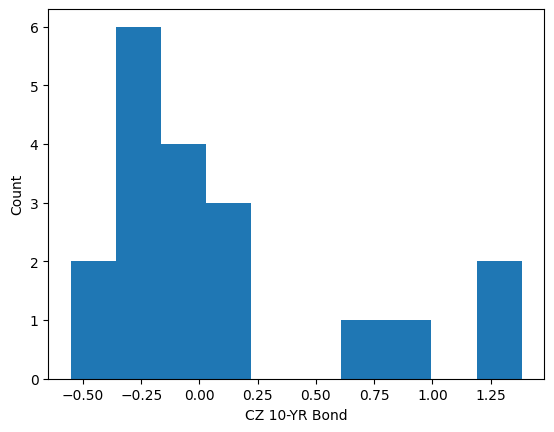

In [104]:
# Histogram
plt.hist(cz_bond["Return"])
plt.ylabel("Count")
plt.xlabel("CZ 10-YR Bond")
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Bonds/CZBond_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

### **German Bonds**

In [12]:
# Load in the Data
GDBR10 = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/Bonds10YR.xlsx", sheet_name="GDBR10")

# Rename Columns
GDBR10.rename(columns={"Unnamed: 0": "Date", "Unnamed: 1": "Total"}, inplace=True)

# Drop first 4 Rows
GDBR10.drop([0,1,2,3], inplace=True)

# Convert Column Date to Date Format
GDBR10["Date"] = pd.to_datetime(GDBR10["Date"])

# Filter "2024-12-31" >= Date >= "2005-01-06" and Reset Index
GDBR10 = GDBR10[(GDBR10["Date"] >= "2005-01-06") & (GDBR10["Date"] <= "2024-12-31")].reset_index().drop("index", axis=1)

In [13]:
# Check for Gaps in the Data

# Create range of all dates
de_range = pd.date_range(start="2005-01-06", end="2024-12-31", freq="B")

# Find missing dates
de_miss = de_range.difference(GDBR10["Date"])

# Missing Values
print(f"In total, there are {len(de_miss)} missing values out of {len(de_range)}.")

In total, there are 5 missing values out of 5214.


In [14]:
# Create "Year" Column
GDBR10["Year"] = pd.DatetimeIndex(GDBR10["Date"]).year

# Drop "Date"
GDBR10.drop("Date", axis=1, inplace=True)

# Average Values in Total and Group by Year 
de_bond = GDBR10.groupby("Year").mean()

# Reset Index
de_bond.reset_index(inplace=True)

In [15]:
# Sort Data by Year
de_bond.sort_values(by="Year", inplace=True)

# Create year-to-year bonds in percentage 
de_bond["Return"] = np.nan
for i in range(1,len(de_bond)):
    de_bond.loc[i, "Return"] = np.round((de_bond.loc[i, "Total"] - de_bond.loc[i-1, "Total"]) / np.abs(de_bond.loc[i-1, "Total"]), 4)

In [16]:
# Check for Outliers
# Calculate mean, std
de_std = np.std(de_bond["Return"])
de_mean = np.mean(de_bond["Return"])

# Calculate Z-Score
de_bond["Z-Score"] = np.nan
for i in range(len(de_bond)):
    de_bond.loc[i, "Z-Score"] = ((de_bond.loc[i, "Return"] - de_mean) / de_std)

# Print out Outliers    
de_bond[np.abs(de_bond["Z-Score"])>3] # Year 2022

,Year,Total,Return,Z-Score
17,2022,1.195062,4.8707,3.598829


In [17]:
# Check for Max Z-Score
de_bond[np.abs(de_bond["Return"]) == np.abs(np.max((de_bond["Return"])))]

,Year,Total,Return,Z-Score
17,2022,1.195062,4.8707,3.598829


In [18]:
# Mean and Variance with 2022
de_mean_new = np.mean(de_bond["Return"])
de_var = np.var(de_bond["Return"])
print(f"German government 10-year bonds have mean {np.round(de_mean_new,4)} and variance {np.round(de_var, 4)}")

German government 10-year bonds have mean 0.1779 and variance 1.7003


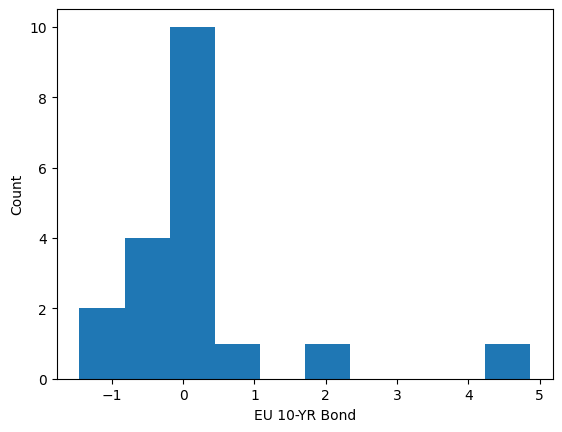

In [19]:
# Histogram
plt.hist(de_bond["Return"])
plt.ylabel("Count")
plt.xlabel("EU 10-YR Bond")
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Bonds/DEBond_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [20]:
# Drop Year 2022
de_bond.drop(17,inplace=True)

# Reset Index
de_bond.reset_index(inplace=True)

# Drop Column index
de_bond.drop("index", axis=1, inplace=True)


In [21]:
# Check for max and min return
de_bond[de_bond["Return"] == np.max((de_bond["Return"]))], de_bond[de_bond["Return"] == np.min(de_bond["Return"])]

(    Year     Total  Return   Z-Score
 12  2017  0.374504  1.7365  1.195248,
     Year     Total  Return   Z-Score
 14  2019 -0.210265  -1.454 -1.251509)

In [22]:
# Mean and Variance without 2022
de_mean_new = np.mean(de_bond["Return"])
de_var = np.var(de_bond["Return"])
print(f"German government 10-year bonds have mean {np.round(de_mean_new,4)} and variance {np.round(de_var, 4)}")

German government 10-year bonds have mean -0.0828 and variance 0.5034


In [33]:
# Save Mean and Variance
params_to_json("DEBond", de_mean_new, de_var)

In [344]:
# Save Data
de_bond.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/DEBonds10YR.xlsx", sheet_name="GDBR10")

### **US Bonds**

In [34]:
# Load in the Data
USGG10YR = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/Bonds10YR.xlsx", sheet_name="USGG10YR")

# Rename Columns
USGG10YR.rename(columns={"Unnamed: 0": "Date", "USA 10Y" : "Total"}, inplace=True)

# Drop first 3 Rows
USGG10YR.drop([0,1,2], inplace=True)

# Convert Column Date to Date Format
USGG10YR["Date"] = pd.to_datetime(USGG10YR["Date"])

# Filter "2024-12-31" >= Date >= "2005-01-06" and Reset Index
USGG10YR = USGG10YR[(USGG10YR["Date"] >= "2005-01-06") & (USGG10YR["Date"] <= "2024-12-31")].reset_index().drop("index", axis=1)

In [35]:
# Check for Gaps in the Data

# Create range of all dates
us_range = pd.date_range(start="2005-01-06", end="2024-12-31", freq="B")

# Find missing dates
us_miss = us_range.difference(USGG10YR["Date"])

# Missing Values
print(f"In total, there are {len(us_miss)} missing values out of {len(us_range)}.")

In total, there are 2 missing values out of 5214.


In [36]:
# Create "Year" Column
USGG10YR["Year"] = pd.DatetimeIndex(USGG10YR["Date"]).year

# Drop "Date"
USGG10YR.drop("Date", axis=1, inplace=True)

# Average Values in Total and Group by Year 
us_bond = USGG10YR.groupby("Year").mean()

# Reset Index
us_bond.reset_index(inplace=True)

In [37]:
# Create year-to-year bonds in percentage 
us_bond["Return"] = np.nan
for i in range(1,len(us_bond)):
    us_bond.loc[i, "Return"] = np.round((us_bond.loc[i, "Total"] - us_bond.loc[i-1, "Total"]) / np.abs(us_bond.loc[i-1, "Total"]), 4)

In [38]:
# Check for Outliers
# Calculate mean, std
us_std = np.std(us_bond["Return"])
us_mean = np.mean(us_bond["Return"])

# Calculate Z-Score
us_bond["Z-Score"] = np.nan
for i in range(len(us_bond)):
    us_bond.loc[i, "Z-Score"] = ((us_bond.loc[i, "Return"] - us_mean) / us_std)

# Print out Outliers    
us_bond[np.abs(us_bond["Z-Score"])>3] # Empty hence no outliers

,Year,Total,Return,Z-Score


In [39]:
# Check for max and min return
us_bond[us_bond["Return"] == np.max((us_bond["Return"]))], us_bond[us_bond["Return"] == np.min(us_bond["Return"])]

(    Year     Total  Return   Z-Score
 17  2022  2.950228  1.0558  2.778925,
     Year     Total  Return   Z-Score
 15  2020  0.890619 -0.5835 -1.784685)

In [168]:
# Save Data
us_bond.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/USBonds10YR.xlsx", sheet_name="USGG10YR")

In [40]:
# Descriptive Statistics
usb_mean=np.mean(us_bond["Return"])
usb_var=np.var(us_bond["Return"])
print(f"Mean value of returns of US bonds is {np.round(usb_mean,4)} and its variance is {np.round(usb_var,4)}")

Mean value of returns of US bonds is 0.0576 and its variance is 0.129


In [41]:
# Save Mean and Variance
params_to_json("USBond", usb_mean, usb_var)

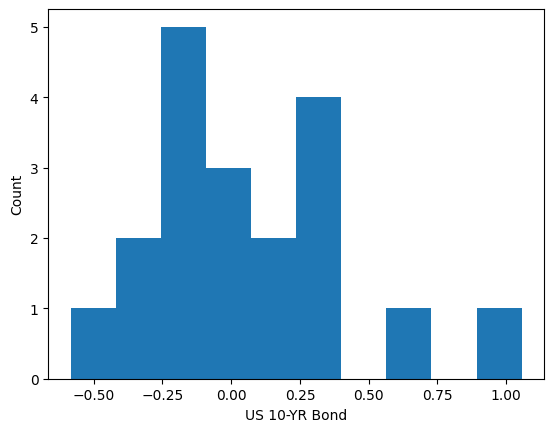

In [169]:
# Histogram
plt.hist(us_bond["Return"])
plt.ylabel("Count")
plt.xlabel("US 10-YR Bond")
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Bonds/USBond_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()